In [38]:
# Walk up to repo root (identified by README.md)
.root <- getwd()
while (!file.exists(file.path(.root, 'README.md')) && dirname(.root) != .root)
  .root <- dirname(.root)
setwd(.root)
rm(.root)

suppressPackageStartupMessages({
  library(tidyverse)
  library(data.table)
  library(arrow)
  library(ggthemes)
  library(scales)
  library(patchwork)
})

options(repr.plot.width = 14, repr.plot.height = 8)

BASE_THEME <- theme_fivethirtyeight() +
  theme(
    axis.title        = element_text(size = 14),
    axis.text         = element_text(size = 13),
    panel.background  = element_rect(fill = "white", color = NA),
    plot.background   = element_rect(fill = "white", color = NA),
    legend.background = element_rect(fill = "white", color = NA),
    legend.text       = element_text(size = 12),
    legend.title      = element_text(size = 13),
    strip.text        = element_text(size = 14, face = "bold"),
    plot.title        = element_text(size = 20, face = "bold"),
    plot.subtitle     = element_text(size = 13)
  )
theme_set(BASE_THEME)

COMMIT_MS  <- 150

PITCH_NAMES <- c(
  FF = "4-Seam",    SI = "Sinker",    FC = "Cutter",
  CH = "Changeup",  FS = "Splitter",
  SL = "Slider",    CU = "Curveball", ST = "Sweeper",   KC = "Knuckle-curve"
)

PITCH_COLORS <- c(
  FF = "#d62728", SI = "#ff7f0e", FC = "#e377c2",
  CH = "#2ca02c", FS = "#17becf",
  SL = "#bcbd22", CU = "#1f77b4", ST = "#9467bd", KC = "#8c564b"
)

In [39]:
df <- as_tibble(fread("data/swings_2023_2025.csv")) |>
  filter(pitch_type %in% names(PITCH_NAMES)) |>
  mutate(
    pitch_name = factor(PITCH_NAMES[pitch_type], levels = unname(PITCH_NAMES)),
    outcome    = case_when(
      is_bip    == 1 ~ "BIP",
      is_contact == 1 ~ "Foul",
      TRUE           ~ "Whiff"
    )
  )

cat(sprintf(
  "Loaded %s swings | Years: %s | Bat-tracked: %.1f%%\n",
  formatC(nrow(df), format = "d", big.mark = ","),
  paste(sort(unique(df$game_year)), collapse = ", "),
  mean(!is.na(df$bat_speed)) * 100
))

Loaded 768,893 swings | Years: 2023, 2024, 2025 | Bat-tracked: 100.0%


## Data Coverage

In [ ]:
# ── Bat tracking coverage by year ─────────────────────────────────────────────
coverage <- df |>
  group_by(game_year) |>
  summarise(
    n_swings    = n(),
    n_tracked   = sum(!is.na(bat_speed)),
    pct_tracked = mean(!is.na(bat_speed)),
    .groups     = "drop"
  )

ggplot(coverage, aes(x = factor(game_year), y = pct_tracked)) +
  geom_col(fill = "#3498db", width = 0.55) +
  geom_text(
    aes(label = sprintf("%s swings\n%.0f%% tracked",
                        formatC(n_swings, format = "d", big.mark = ","),
                        pct_tracked * 100)),
    vjust = -0.25, size = 4.5, lineheight = 1.1
  ) +
  scale_y_continuous(labels = percent_format(), limits = c(0, 1.15)) +
  labs(
    title    = "Bat Tracking Coverage by Season",
    subtitle = "Hawk-Eye bat tracking rolled out mid-2023",
    x        = "Season", y = "% Swings with Bat Tracking"
  )

In [ ]:
# ── Pitch type distribution ────────────────────────────────────────────────────
pitch_dist <- df |>
  count(pitch_type) |>
  mutate(pitch_name = PITCH_NAMES[pitch_type]) |>
  arrange(desc(n))

ggplot(pitch_dist,
       aes(x = reorder(pitch_name, n), y = n, fill = pitch_type)) +
  geom_col(width = 0.65) +
  geom_text(aes(label = formatC(n, format = "d", big.mark = ",")),
            hjust = -0.1, size = 4.3) +
  scale_fill_manual(values = PITCH_COLORS, guide = "none") +
  scale_y_continuous(expand = expansion(mult = c(0, 0.18)),
                     labels = comma_format()) +
  coord_flip() +
  labs(
    title    = "Swings by Pitch Type",
    subtitle = "2023–2025",
    x        = NULL, y = "Number of Swings"
  )

## Swing Outcomes

In [ ]:
# ── Swing outcome rates by pitch type ─────────────────────────────────────────
outcome_rates <- df |>
  group_by(pitch_name) |>
  summarise(
    n      = n(),
    whiff  = mean(outcome == "Whiff"),
    foul   = mean(outcome == "Foul"),
    bip    = mean(outcome == "BIP"),
    .groups = "drop"
  ) |>
  pivot_longer(c(whiff, foul, bip), names_to = "outcome", values_to = "rate") |>
  mutate(outcome = factor(outcome, levels = c("bip", "foul", "whiff"),
                          labels = c("Ball in Play", "Foul", "Whiff")))

ggplot(outcome_rates,
       aes(x = reorder(pitch_name, -rate * (outcome == "Whiff")),
           y = rate, fill = outcome)) +
  geom_col(width = 0.7) +
  scale_fill_manual(
    values = c("Ball in Play" = "#2ecc71", "Foul" = "#f39c12", "Whiff" = "#e74c3c"),
    name   = NULL
  ) +
  scale_y_continuous(labels = percent_format()) +
  labs(
    title    = "Swing Outcome Rates by Pitch Type",
    x        = NULL, y = "Rate"
  ) +
  theme(axis.text.x = element_text(angle = 30, hjust = 1),
        legend.position = "top")

In [ ]:
# ── Overall outcome distribution ──────────────────────────────────────────────
overall <- df |>
  count(outcome) |>
  mutate(pct = n / sum(n))

ggplot(overall, aes(x = outcome, y = pct, fill = outcome)) +
  geom_col(width = 0.55) +
  geom_text(aes(label = sprintf("%.1f%%\n(%s)", pct * 100,
                                 formatC(n, format = "d", big.mark = ","))),
            vjust = -0.2, size = 4.5, lineheight = 1.1) +
  scale_fill_manual(
    values = c("BIP" = "#2ecc71", "Foul" = "#f39c12", "Whiff" = "#e74c3c"),
    guide  = "none"
  ) +
  scale_y_continuous(labels = percent_format(), limits = c(0, 0.55)) +
  labs(title = "Overall Swing Outcome Distribution", x = NULL, y = "Rate")

## Plate Location

In [ ]:
# ── Plate location density — Whiff ────────────────────────────────────────────
sz <- data.frame(xmin = -0.83, xmax = 0.83, ymin = 1.5, ymax = 3.5)

df |>
  filter(outcome == "Whiff", !is.na(plate_x), !is.na(plate_z),
         between(plate_x, -2.5, 2.5), between(plate_z, 0.5, 5)) |>
  ggplot(aes(x = plate_x, y = plate_z)) +
  stat_density_2d_filled(contour_var = "ndensity", bins = 12, alpha = 0.85) +
  geom_rect(data = sz, aes(xmin = xmin, xmax = xmax, ymin = ymin, ymax = ymax),
            inherit.aes = FALSE, fill = NA, color = "white",
            linewidth = 0.8, linetype = "dashed") +
  scale_fill_viridis_d(option = "magma", guide = "none") +
  coord_fixed() +
  labs(
    title    = "Plate Location — Whiff",
    subtitle = "Dashed box = approximate strike zone  |  catcher's perspective",
    x = "Horizontal location (ft)", y = "Vertical location (ft)"
  )

In [ ]:
# ── Plate location density — Foul ─────────────────────────────────────────────
df |>
  filter(outcome == "Foul", !is.na(plate_x), !is.na(plate_z),
         between(plate_x, -2.5, 2.5), between(plate_z, 0.5, 5)) |>
  ggplot(aes(x = plate_x, y = plate_z)) +
  stat_density_2d_filled(contour_var = "ndensity", bins = 12, alpha = 0.85) +
  geom_rect(data = sz, aes(xmin = xmin, xmax = xmax, ymin = ymin, ymax = ymax),
            inherit.aes = FALSE, fill = NA, color = "white",
            linewidth = 0.8, linetype = "dashed") +
  scale_fill_viridis_d(option = "magma", guide = "none") +
  coord_fixed() +
  labs(
    title    = "Plate Location — Foul",
    subtitle = "Dashed box = approximate strike zone  |  catcher's perspective",
    x = "Horizontal location (ft)", y = "Vertical location (ft)"
  )

In [ ]:
# ── Plate location density — Ball in Play ─────────────────────────────────────
df |>
  filter(outcome == "BIP", !is.na(plate_x), !is.na(plate_z),
         between(plate_x, -2.5, 2.5), between(plate_z, 0.5, 5)) |>
  ggplot(aes(x = plate_x, y = plate_z)) +
  stat_density_2d_filled(contour_var = "ndensity", bins = 12, alpha = 0.85) +
  geom_rect(data = sz, aes(xmin = xmin, xmax = xmax, ymin = ymin, ymax = ymax),
            inherit.aes = FALSE, fill = NA, color = "white",
            linewidth = 0.8, linetype = "dashed") +
  scale_fill_viridis_d(option = "magma", guide = "none") +
  coord_fixed() +
  labs(
    title    = "Plate Location — Ball in Play",
    subtitle = "Dashed box = approximate strike zone  |  catcher's perspective",
    x = "Horizontal location (ft)", y = "Vertical location (ft)"
  )

## Count Profile

In [ ]:
# ── Swing volume and whiff rate by count — heatmap ────────────────────────────
count_profile <- df |>
  filter(balls <= 3, strikes <= 2) |>
  group_by(balls, strikes) |>
  summarise(
    n          = n(),
    whiff_rate = mean(outcome == "Whiff"),
    .groups    = "drop"
  ) |>
  mutate(
    count_label = sprintf("%d-%d", balls, strikes),
    count_type  = case_when(
      strikes == 2 & balls < 3   ~ "Two strikes",
      balls == 3  & strikes < 2  ~ "Three balls",
      balls == 3  & strikes == 2 ~ "Full",
      balls == 0  & strikes == 0 ~ "First pitch",
      TRUE                       ~ "Neutral"
    )
  )

ggplot(count_profile,
       aes(x = factor(strikes), y = factor(balls), fill = n)) +
  geom_tile(color = "white", linewidth = 1) +
  geom_text(aes(label = sprintf("%s\n%.0f%%",
                                 formatC(n, format = "d", big.mark = ","),
                                 whiff_rate * 100)),
            size = 4.5, color = "white", fontface = "bold", lineheight = 1.2) +
  scale_fill_gradient(low = "#3498db", high = "#c0392b",
                      name = "Swings", labels = comma_format()) +
  scale_x_discrete(labels = c("0 K", "1 K", "2 K")) +
  scale_y_discrete(labels = c("0 BB", "1 BB", "2 BB", "3 BB")) +
  labs(
    title    = "Swing Volume & Whiff Rate by Count",
    subtitle = "Cell text: swing count + whiff%",
    x = "Strikes", y = "Balls"
  )

In [ ]:
# ── Whiff rate by count — bar chart ───────────────────────────────────────────
ggplot(count_profile,
       aes(x = reorder(count_label, whiff_rate), y = whiff_rate,
           fill = count_type)) +
  geom_col(width = 0.65) +
  geom_text(aes(label = sprintf("%.1f%%", whiff_rate * 100)),
            hjust = -0.1, size = 4.3) +
  scale_y_continuous(labels = percent_format(), expand = expansion(mult = c(0, 0.18))) +
  scale_fill_brewer(palette = "Set2", name = NULL) +
  coord_flip() +
  labs(
    title    = "Whiff Rate by Count",
    x        = NULL, y = "Whiff rate"
  ) +
  theme(legend.position = "top")

## Bat Speed & Swing Metrics

In [ ]:
# ── Bat speed distribution by outcome ─────────────────────────────────────────
tracked <- df |> filter(!is.na(bat_speed), !is.na(swing_length))

ggplot(tracked, aes(x = bat_speed, fill = outcome, color = outcome)) +
  geom_density(alpha = 0.25, linewidth = 0.9) +
  scale_fill_manual(values = c("BIP" = "#2ecc71", "Foul" = "#f39c12", "Whiff" = "#e74c3c"), name = NULL) +
  scale_color_manual(values = c("BIP" = "#2ecc71", "Foul" = "#f39c12", "Whiff" = "#e74c3c"), name = NULL) +
  labs(
    title    = "Bat Speed by Swing Outcome",
    subtitle = sprintf("Bat-tracked swings only  (n = %s)",
                       formatC(nrow(tracked), format = "d", big.mark = ",")),
    x = "Bat speed (mph)", y = "Density"
  ) +
  theme(legend.position = "top")

In [ ]:
# ── Swing length distribution by outcome ──────────────────────────────────────
ggplot(tracked, aes(x = swing_length, fill = outcome, color = outcome)) +
  geom_density(alpha = 0.25, linewidth = 0.9) +
  scale_fill_manual(values = c("BIP" = "#2ecc71", "Foul" = "#f39c12", "Whiff" = "#e74c3c"), name = NULL) +
  scale_color_manual(values = c("BIP" = "#2ecc71", "Foul" = "#f39c12", "Whiff" = "#e74c3c"), name = NULL) +
  labs(
    title = "Swing Length by Swing Outcome",
    x = "Swing length (ft)", y = "Density"
  ) +
  theme(legend.position = "top")

In [ ]:
# ── Bat speed vs swing length scatter ─────────────────────────────────────────
set.seed(42)
samp_track <- slice_sample(tracked, n = 20000)

ggplot(samp_track, aes(x = swing_length, y = bat_speed, color = outcome)) +
  geom_point(alpha = 0.08, size = 0.6) +
  scale_color_manual(values = c("BIP" = "#2ecc71", "Foul" = "#f39c12", "Whiff" = "#e74c3c"),
                     name = NULL, guide = "none") +
  labs(
    title    = "Bat Speed vs Swing Length",
    subtitle = "20k sample",
    x = "Swing length (ft)", y = "Bat speed (mph)"
  )

## Predictors Driving Swing Shape

In [ ]:
# ── Count effect on vertical attack angle ─────────────────────────────────────
vaa_count <- df |>
  filter(!is.na(vert_attack_angle), balls <= 3, strikes <= 2) |>
  group_by(balls, strikes) |>
  summarise(
    mean_vaa = mean(vert_attack_angle),
    se_vaa   = sd(vert_attack_angle) / sqrt(n()),
    .groups  = "drop"
  ) |>
  mutate(count_label = sprintf("%d-%d", balls, strikes))

ggplot(vaa_count, aes(x = reorder(count_label, mean_vaa), y = mean_vaa)) +
  geom_col(aes(fill = mean_vaa), width = 0.65, show.legend = FALSE) +
  geom_errorbar(aes(ymin = mean_vaa - 1.96 * se_vaa,
                    ymax = mean_vaa + 1.96 * se_vaa), width = 0.2) +
  scale_fill_gradient2(low = "#2980b9", mid = "grey80", high = "#c0392b", midpoint = 0) +
  coord_flip() +
  labs(
    title    = "Mean Vertical Attack Angle by Count",
    subtitle = "Two-strike counts produce steeper (more negative) attack angles",
    x = NULL, y = "Mean vertical attack angle (°)"
  )

In [ ]:
# ── Plate height vs vertical attack angle ─────────────────────────────────────
set.seed(42)
samp_vaa <- df |>
  filter(!is.na(vert_attack_angle), !is.na(plate_z),
         between(plate_z, 0.5, 5)) |>
  slice_sample(n = 30000)

ggplot(samp_vaa, aes(x = plate_z, y = vert_attack_angle)) +
  geom_bin2d(bins = 40) +
  geom_smooth(method = "gam", color = "#e74c3c", linewidth = 1.1, se = FALSE) +
  scale_fill_viridis_c(option = "magma", name = "Count") +
  labs(
    title    = "Plate Height vs Vertical Attack Angle",
    subtitle = "Higher pitches → steeper attack angle (30k sample)",
    x = "Plate height (ft)", y = "Vertical attack angle (°)"
  )

## Batter Heterogeneity

In [ ]:
# ── Distribution of batter-level mean VAA ────────────────────────────────────
batter_means <- df |>
  filter(!is.na(vert_attack_angle), !is.na(bat_speed)) |>
  group_by(batter_id) |>
  filter(n() >= 100) |>
  summarise(
    mean_vaa       = mean(vert_attack_angle),
    mean_bat_speed = mean(bat_speed),
    n              = n(),
    .groups        = "drop"
  )

ggplot(batter_means, aes(x = mean_vaa)) +
  geom_histogram(bins = 50, fill = "#3498db", color = "white", linewidth = 0.3) +
  geom_vline(xintercept = mean(batter_means$mean_vaa),
             linetype = "dashed", color = "#c0392b", linewidth = 1) +
  annotate("text",
           x = mean(batter_means$mean_vaa) + 0.3, y = Inf,
           vjust = 1.5, hjust = 0, size = 4, color = "#c0392b",
           label = sprintf("mean = %.1f°", mean(batter_means$mean_vaa))) +
  labs(
    title    = "Distribution of Batter-Level Mean VAA",
    subtitle = sprintf("n = %d batters (≥100 swings) — wide spread justifies per-batter random effects",
                       nrow(batter_means)),
    x = "Batter mean vertical attack angle (°)", y = "Batters"
  )

In [ ]:
# ── Distribution of batter-level mean bat speed ───────────────────────────────
ggplot(batter_means, aes(x = mean_bat_speed)) +
  geom_histogram(bins = 50, fill = "#e67e22", color = "white", linewidth = 0.3) +
  geom_vline(xintercept = mean(batter_means$mean_bat_speed),
             linetype = "dashed", color = "#c0392b", linewidth = 1) +
  annotate("text",
           x = mean(batter_means$mean_bat_speed) + 0.3, y = Inf,
           vjust = 1.5, hjust = 0, size = 4, color = "#c0392b",
           label = sprintf("mean = %.1f mph", mean(batter_means$mean_bat_speed))) +
  labs(
    title    = "Distribution of Batter-Level Mean Bat Speed",
    subtitle = sprintf("n = %d batters (≥100 swings)", nrow(batter_means)),
    x = "Batter mean bat speed (mph)", y = "Batters"
  )

In [ ]:
# ── Two-strike VAA adjustment heterogeneity ───────────────────────────────────
batter_count_adj <- df |>
  filter(!is.na(vert_attack_angle), balls <= 3, strikes <= 2) |>
  group_by(batter_id) |>
  filter(n() >= 200) |>
  summarise(
    vaa_0strike = mean(vert_attack_angle[strikes == 0], na.rm = TRUE),
    vaa_2strike = mean(vert_attack_angle[strikes == 2], na.rm = TRUE),
    .groups     = "drop"
  ) |>
  filter(!is.na(vaa_0strike), !is.na(vaa_2strike)) |>
  mutate(two_strike_adj = vaa_2strike - vaa_0strike)

ggplot(batter_count_adj, aes(x = two_strike_adj)) +
  geom_histogram(bins = 50, fill = "#9b59b6", color = "white", linewidth = 0.3) +
  geom_vline(xintercept = 0, linetype = "dashed", color = "grey40", linewidth = 0.8) +
  geom_vline(xintercept = mean(batter_count_adj$two_strike_adj),
             linetype = "dashed", color = "#c0392b", linewidth = 1) +
  labs(
    title    = "Batter Two-Strike VAA Adjustment",
    subtitle = "VAA(2 strikes) − VAA(0 strikes) | wide spread → count-slope random effect needed",
    x = "Two-strike VAA adjustment (°)", y = "Batters"
  )

## Missing Data Structure

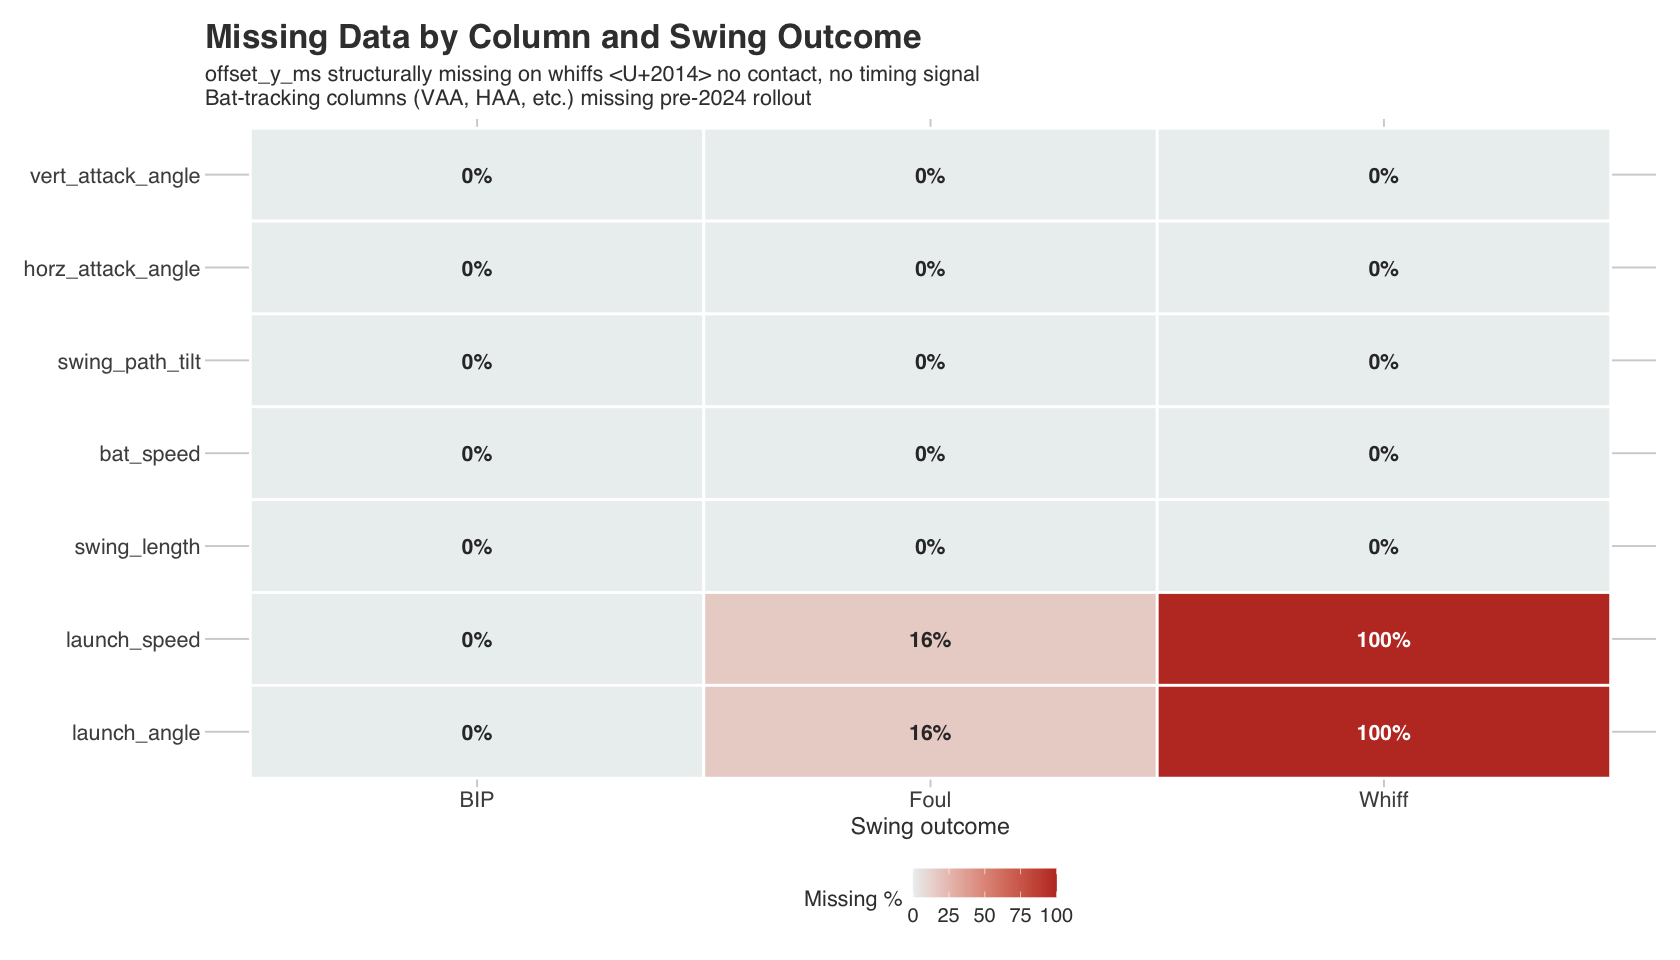

In [46]:
# ── Missingness rates by column and swing outcome ─────────────────────────────
# offset_y_ms is structurally missing on whiffs (no contact = no timing signal)
# This is NOT random missingness — the model must handle it explicitly
key_cols <- c(
  "vert_attack_angle", "horz_attack_angle", "swing_path_tilt",
  "bat_speed", "swing_length",
  "offset_y_ms",
  "launch_speed", "launch_angle"
)
# Keep only columns that exist in this dataset
present_cols <- intersect(key_cols, names(df))

miss_by_outcome <- df |>
  select(outcome, any_of(key_cols)) |>
  group_by(outcome) |>
  summarise(across(any_of(key_cols), ~ mean(is.na(.))), .groups = "drop") |>
  pivot_longer(-outcome, names_to = "column", values_to = "miss_rate") |>
  mutate(
    column   = factor(column, levels = rev(key_cols)),
    miss_pct = miss_rate * 100
  )

ggplot(miss_by_outcome, aes(x = outcome, y = column, fill = miss_pct)) +
  geom_tile(color = "white", linewidth = 0.8) +
  geom_text(aes(label = sprintf("%.0f%%", miss_pct),
                color = miss_pct > 50),
            size = 4.5, fontface = "bold") +
  scale_fill_gradient(low = "#ecf0f1", high = "#c0392b",
                      name = "Missing %", limits = c(0, 100)) +
  scale_color_manual(values = c("FALSE" = "grey20", "TRUE" = "white"),
                     guide = "none") +
  labs(
    title    = "Missing Data by Column and Swing Outcome",
    subtitle = "offset_y_ms structurally missing on whiffs — no contact, no timing signal\nBat-tracking columns (VAA, HAA, etc.) missing pre-2024 rollout",
    x        = "Swing outcome", y = NULL
  )

## EV / LA Joint Distribution and Run Value Surface

In [ ]:
# ── EV / LA joint distribution ────────────────────────────────────────────────
bip <- df |>
  filter(is_bip == 1, !is.na(launch_speed), !is.na(launch_angle),
         !is.na(delta_run_exp))

ggplot(bip, aes(x = launch_speed, y = launch_angle)) +
  geom_bin2d(bins = 60) +
  annotate("rect", xmin = 98, xmax = Inf, ymin = 26, ymax = 30,
           fill = NA, color = "#e74c3c", linewidth = 1, linetype = "dashed") +
  annotate("text", x = 99, y = 28, label = "Barrel\nzone",
           color = "#e74c3c", size = 3.8, fontface = "bold", hjust = 0) +
  scale_fill_viridis_c(option = "magma", name = "BIP count", trans = "log10") +
  labs(
    title    = "Exit Velocity / Launch Angle Joint Distribution",
    subtitle = "Ball in play only",
    x = "Exit velocity (mph)", y = "Launch angle (°)"
  )

In [ ]:
# ── Run value surface (EV × LA) ───────────────────────────────────────────────
rv_surface <- bip |>
  mutate(
    ev_bin = cut(launch_speed, breaks = seq(40, 120, by = 5),
                 include.lowest = TRUE, right = FALSE),
    la_bin = cut(launch_angle, breaks = seq(-90, 90, by = 10),
                 include.lowest = TRUE, right = FALSE)
  ) |>
  group_by(ev_bin, la_bin) |>
  summarise(mean_rv = mean(delta_run_exp), n = n(), .groups = "drop") |>
  filter(n >= 20)

ggplot(rv_surface, aes(x = ev_bin, y = la_bin, fill = mean_rv)) +
  geom_tile() +
  scale_fill_gradient2(
    low = "#c0392b", mid = "white", high = "#2ecc71", midpoint = 0,
    name = "Mean\nrun value"
  ) +
  scale_x_discrete(breaks = levels(rv_surface$ev_bin)[seq(1, nlevels(rv_surface$ev_bin), 2)]) +
  theme(axis.text.x = element_text(angle = 45, hjust = 1, size = 10)) +
  labs(
    title    = "Run Value Surface (EV × LA)",
    subtitle = "Green = positive run value | red = negative | non-linear structure motivates EV/LA as explicit intermediates",
    x = "Exit velocity bin (mph)", y = "Launch angle bin (°)"
  )

## Raw Correlation: Post-Commit Deviation vs Outcomes

In [ ]:
# ── Swing outcomes by post-commit deviation quartile ──────────────────────────
pc_raw <- read_parquet("data/swings_precommit.parquet") |>
  select(game_pk, at_bat_number, pitch_number,
         pc150_emp_dev_x, pc150_emp_dev_z)

df_pc <- as_tibble(fread("data/swings_2023_2025.csv")) |>
  filter(pitch_type %in% names(PITCH_NAMES)) |>
  mutate(outcome = case_when(
    is_bip    == 1 ~ "BIP",
    is_contact == 1 ~ "Foul",
    TRUE           ~ "Whiff"
  )) |>
  left_join(pc_raw, by = c("game_pk", "at_bat_number", "pitch_number")) |>
  mutate(emp_dev_total = sqrt(pc150_emp_dev_x^2 + pc150_emp_dev_z^2)) |>
  filter(!is.na(emp_dev_total))

dev_quartile <- df_pc |>
  mutate(dev_q = ntile(emp_dev_total, 4),
         dev_label = factor(dev_q,
           labels = c("Q1\n(least)", "Q2", "Q3", "Q4\n(most)"))) |>
  group_by(dev_label) |>
  summarise(
    whiff_rate = mean(outcome == "Whiff"),
    bip_rate   = mean(outcome == "BIP"),
    n          = n(),
    .groups    = "drop"
  ) |>
  pivot_longer(c(whiff_rate, bip_rate), names_to = "metric", values_to = "rate") |>
  mutate(metric = recode(metric, whiff_rate = "Whiff rate", bip_rate = "BIP rate"))

ggplot(dev_quartile, aes(x = dev_label, y = rate, color = metric, group = metric)) +
  geom_line(linewidth = 1.2) +
  geom_point(size = 4) +
  scale_color_manual(values = c("Whiff rate" = "#e74c3c", "BIP rate" = "#2ecc71"),
                     name = NULL) +
  scale_y_continuous(labels = percent_format()) +
  labs(
    title    = "Swing Outcomes by Post-Commit Deviation Quartile",
    subtitle = "More late movement → more whiffs, fewer BIP",
    x = "Post-commit deviation quartile", y = "Rate"
  ) +
  theme(legend.position = "top")

In [ ]:
# ── Mean post-commit deviation by pitch type × outcome ────────────────────────
dev_by_outcome <- df_pc |>
  group_by(pitch_name = PITCH_NAMES[pitch_type], outcome) |>
  summarise(mean_dev = mean(emp_dev_total), .groups = "drop") |>
  filter(!is.na(pitch_name))

ggplot(dev_by_outcome,
       aes(x = reorder(pitch_name, mean_dev), y = mean_dev, fill = outcome)) +
  geom_col(position = "dodge", width = 0.7) +
  scale_fill_manual(values = c("BIP" = "#2ecc71", "Foul" = "#f39c12", "Whiff" = "#e74c3c"),
                    name = NULL) +
  coord_flip() +
  scale_y_continuous(expand = expansion(mult = c(0, 0.1))) +
  labs(
    title    = "Mean Post-Commit Deviation by Pitch Type and Outcome",
    subtitle = "Whiffs tend to have higher deviation than BIP for the same pitch type",
    x = NULL, y = "Mean emp_dev_total (ft)"
  ) +
  theme(legend.position = "top")